# Retail Sales Data Analysis

This project analyzes retail sales data to identify sales trends, profitability patterns, customer behavior, and business opportunities.

## 1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import sys
print(sys.executable)

/home/tara/retail-sales-project/.venv/bin/python


## 2. Loading the Dataset

In [3]:
df = pd.read_csv(
    "../data/Sample - Superstore.csv",
    encoding="latin1"
)

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 3. Data Inspection

In [4]:
df.shape

(9994, 21)

In [5]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

## 4. Data Cleaning and Preprocessing

In [9]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [10]:
df[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

## 5. Exploratory Data Analysis (EDA)

In [11]:
df[["Sales", "Quantity", "Discount", "Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [12]:
(df["Profit"] < 0).sum()

np.int64(1871)

In [13]:
(df["Discount"] == 0.8).sum()

np.int64(300)

## 6. Discount Analysis

In [14]:
df.groupby("Discount")["Profit"].agg(["count", "mean", "sum"])

,count,mean,sum
Discount,,,
0.00,4798,66.900292,320987.6032
0.10,94,96.055074,9029.1770
0.15,52,27.288298,1418.9915
0.20,3657,24.702572,90337.3060
0.30,227,-45.679636,-10369.2774
0.32,27,-88.560656,-2391.1377
0.40,206,-111.927429,-23057.0504
0.45,11,-226.646464,-2493.1111
0.50,66,-310.703456,-20506.4281


In [15]:
df.pivot_table(
    index="Discount",
    columns="Category",
    values="Profit",
    aggfunc="mean"
)

Category,Furniture,Office Supplies,Technology
Discount,,,
0.00,69.537173,41.708567,158.881657
0.10,93.565946,67.880050,416.042150
0.15,27.288298,NaN,NaN
0.20,10.188535,17.282486,54.735560
0.30,-48.177103,NaN,65.207900
0.32,-88.560656,NaN,NaN
0.40,-215.831957,NaN,-52.440104
0.45,-226.646464,NaN,NaN
0.50,-238.355537,NaN,-636.269092


In [16]:
df.pivot_table(
    index="Discount",
    columns="Category",
    values="Profit",
    aggfunc="count"
)

Category,Furniture,Office Supplies,Technology
Discount,,,
0.00,836.0,3129.0,833.0
0.10,76.0,16.0,2.0
0.15,52.0,NaN,NaN
0.20,615.0,2201.0,841.0
0.30,222.0,NaN,5.0
0.32,27.0,NaN,NaN
0.40,75.0,NaN,131.0
0.45,11.0,NaN,NaN
0.50,54.0,NaN,12.0


## 7. Category and Sub-Category Analysis

In [17]:
df.groupby("Sub-Category")["Profit"].agg(
    ["count", "sum", "mean"]
).sort_values("sum")

,count,sum,mean
Sub-Category,,,
Tables,319,-17725.4811,-55.565771
Bookcases,228,-3472.5560,-15.230509
Supplies,190,-1189.0995,-6.258418
Fasteners,217,949.5182,4.375660
Machines,115,3384.7569,29.432669
Labels,364,5546.2540,15.236962
Art,796,6527.7870,8.200737
Envelopes,254,6964.1767,27.418019
Furnishings,957,13059.1436,13.645918


In [18]:
df[df["Sub-Category"] == "Tables"].groupby("Discount")["Profit"].agg(
    ["count", "mean", "sum"]
)

,count,mean,sum
Discount,,,
0.00,72,184.393051,13276.2997
0.20,71,-4.275465,-303.5580
0.30,54,-63.006067,-3402.3276
0.40,75,-215.831957,-16187.3968
0.45,11,-226.646464,-2493.1111
0.50,36,-239.316314,-8615.3873


In [19]:
df[df["Sub-Category"] == "Tables"].groupby("Product Name")["Profit"].agg(
    ["count", "sum", "mean"]
).sort_values("sum").head(10)

,count,sum,mean
Product Name,,,
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,5,-2876.1156,-575.223120
Bush Advantage Collection Racetrack Conference Table,7,-1934.3976,-276.342514
Balt Solid Wood Round Tables,4,-1201.0581,-300.264525
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables,3,-1148.4375,-382.812500
"Riverside Furniture Oval Coffee Table, Oval End Table, End Table with Drawer",5,-1147.4000,-229.480000
Bretford Just In Time Height-Adjustable Multi-Task Work Tables,4,-964.1940,-241.048500
"Bevis Oval Conference Table, Walnut",8,-856.0144,-107.001800
BPI Conference Tables,5,-795.9725,-159.194500
Hon 94000 Series Round Tables,5,-681.2140,-136.242800


In [20]:
df[df["Product Name"] == "Chromcraft Bull-Nose Wood Oval Conference Tables & Bases"][
    ["Order ID", "Order Date", "Sales", "Quantity", "Discount", "Profit"]
].sort_values("Profit")

,Order ID,Order Date,Sales,Quantity,Discount,Profit
9639,CA-2015-116638,2015-01-28,4297.644,13,0.4,-1862.3124
5320,US-2017-162558,2017-10-02,2314.116,7,0.4,-1002.7836
9899,US-2014-117380,2014-03-28,330.588,1,0.4,-143.2548
2477,CA-2017-102750,2017-09-04,1322.352,3,0.2,-99.1764
721,CA-2016-142335,2016-12-15,1652.940,3,0.0,231.4116


In [21]:
df[df["Product Name"] == "Chromcraft Bull-Nose Wood Oval Conference Tables & Bases"].assign(
    Profit_Per_Unit=lambda x: x["Profit"] / x["Quantity"]
)[["Quantity", "Discount", "Profit", "Profit_Per_Unit"]]

,Quantity,Discount,Profit,Profit_Per_Unit
721,3,0.0,231.4116,77.1372
2477,3,0.2,-99.1764,-33.0588
5320,7,0.4,-1002.7836,-143.2548
9639,13,0.4,-1862.3124,-143.2548
9899,1,0.4,-143.2548,-143.2548


In [22]:
df[df["Sub-Category"] == "Tables"].groupby(
    "Product Name"
).agg(
    Total_Quantity=("Quantity", "sum"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Discount=("Discount", "mean")
).sort_values("Total_Profit").head(10)

,Total_Quantity,Total_Sales,Total_Profit,Average_Discount
Product Name,,,,
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,27,9917.6400,-2876.1156,0.280000
Bush Advantage Collection Racetrack Conference Table,33,9544.7250,-1934.3976,0.350000
Balt Solid Wood Round Tables,19,6518.7540,-1201.0581,0.200000
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables,15,1706.2500,-1148.4375,0.483333
"Riverside Furniture Oval Coffee Table, Oval End Table, End Table with Drawer",25,4446.1750,-1147.4000,0.300000
Bretford Just In Time Height-Adjustable Multi-Task Work Tables,17,5634.9000,-964.1940,0.225000
"Bevis Oval Conference Table, Walnut",36,6942.0680,-856.0144,0.275000
BPI Conference Tables,26,2241.8675,-795.9725,0.370000
Hon 94000 Series Round Tables,30,7404.5000,-681.2140,0.160000


In [23]:
tables_analysis = df[df["Sub-Category"] == "Tables"].groupby(
    "Product Name"
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Discount=("Discount", "mean")
)

tables_analysis["Profit_Margin"] = (
    tables_analysis["Total_Profit"] / tables_analysis["Total_Sales"]
) * 100

tables_analysis.sort_values("Profit_Margin").head(10)

,Total_Sales,Total_Profit,Average_Discount,Profit_Margin
Product Name,,,,
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables,1706.2500,-1148.4375,0.483333,-67.307692
Bevis Rectangular Conference Tables,1007.2620,-586.8396,0.475000,-58.260870
Riverside Furniture Stanwyck Manor Table Series,917.9200,-415.9325,0.366667,-45.312500
BPI Conference Tables,2241.8675,-795.9725,0.370000,-35.504886
Balt Split Level Computer Training Table,1040.6250,-357.9750,0.380000,-34.400000
Anderson Hickey Conga Table Tops & Accessories,51.7820,-17.5145,0.300000,-33.823529
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.6400,-2876.1156,0.280000,-29.000000
Balt Solid Wood Rectangular Table,828.0965,-216.2545,0.262500,-26.114650
"Riverside Furniture Oval Coffee Table, Oval End Table, End Table with Drawer",4446.1750,-1147.4000,0.300000,-25.806452


## 8. Monthly Sales and Profit Analysis

In [24]:
df["Order Month"] = df["Order Date"].dt.to_period("M")

monthly_analysis = df.groupby("Order Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

monthly_analysis.head(12)

,Total_Sales,Total_Profit,Total_Orders
Order Month,,,
2014-01,14236.8950,2450.1907,32
2014-02,4519.8920,862.3084,28
2014-03,55691.0090,498.7299,71
2014-04,28295.3450,3488.8352,66
2014-05,23648.2870,2738.7096,69
2014-06,34595.1276,4976.5244,66
2014-07,33946.3930,-841.4826,65
2014-08,27909.4685,5318.1050,72
2014-09,81777.3508,8328.0994,130


In [25]:
monthly_analysis["Average_Order_Value"] = (
    monthly_analysis["Total_Sales"] /
    monthly_analysis["Total_Orders"]
)

monthly_analysis

,Total_Sales,Total_Profit,Total_Orders,Average_Order_Value
Order Month,,,,
2014-01,14236.8950,2450.1907,32,444.902969
2014-02,4519.8920,862.3084,28,161.424714
2014-03,55691.0090,498.7299,71,784.380408
2014-04,28295.3450,3488.8352,66,428.717348
2014-05,23648.2870,2738.7096,69,342.728797
2014-06,34595.1276,4976.5244,66,524.168600
2014-07,33946.3930,-841.4826,65,522.252200
2014-08,27909.4685,5318.1050,72,387.631507
2014-09,81777.3508,8328.0994,130,629.056545


## 9. Yearly Performance Analysis

In [26]:
yearly_analysis = monthly_analysis.groupby(
    monthly_analysis.index.year
).agg(
    Total_Sales=("Total_Sales", "sum"),
    Total_Profit=("Total_Profit", "sum"),
    Total_Orders=("Total_Orders", "sum")
)

yearly_analysis["Average_Order_Value"] = (
    yearly_analysis["Total_Sales"] /
    yearly_analysis["Total_Orders"]
)

yearly_analysis["Profit_Margin"] = (
    yearly_analysis["Total_Profit"] /
    yearly_analysis["Total_Sales"]
) * 100

yearly_analysis

,Total_Sales,Total_Profit,Total_Orders,Average_Order_Value,Profit_Margin
Order Month,,,,,
2014,484247.4981,49543.9741,969,499.739420,10.231126
2015,470532.5090,61618.6037,1038,453.306849,13.095504
2016,609205.5980,81795.1743,1315,463.274219,13.426530
2017,733215.2552,93439.2696,1687,434.626707,12.743771


In [27]:
yearly_analysis["Sales_Growth_%"] = (
    yearly_analysis["Total_Sales"].pct_change() * 100
)

yearly_analysis["Profit_Growth_%"] = (
    yearly_analysis["Total_Profit"].pct_change() * 100
)

yearly_analysis["Orders_Growth_%"] = (
    yearly_analysis["Total_Orders"].pct_change() * 100
)

yearly_analysis

,Total_Sales,Total_Profit,Total_Orders,Average_Order_Value,Profit_Margin,Sales_Growth_%,Profit_Growth_%,Orders_Growth_%
Order Month,,,,,,,,
2014,484247.4981,49543.9741,969,499.739420,10.231126,NaN,NaN,NaN
2015,470532.5090,61618.6037,1038,453.306849,13.095504,-2.832227,24.371540,7.120743
2016,609205.5980,81795.1743,1315,463.274219,13.426530,29.471521,32.744284,26.685934
2017,733215.2552,93439.2696,1687,434.626707,12.743771,20.355962,14.235675,28.288973


## 10. Regional Analysis

In [28]:
regional_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

regional_analysis["Profit_Margin"] = (
    regional_analysis["Total_Profit"] /
    regional_analysis["Total_Sales"]
) * 100

regional_analysis.sort_values(
    "Total_Sales",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Orders,Profit_Margin
Region,,,,
West,725457.8245,108418.4489,1611,14.944831
East,678781.2400,91522.7800,1401,13.483399
Central,501239.8908,39706.3625,1175,7.921629
South,391721.9050,46749.4303,822,11.934342


In [29]:
region_category_analysis = df.pivot_table(
    index="Region",
    columns="Category",
    values="Profit",
    aggfunc="sum"
)

region_category_analysis

Category,Furniture,Office Supplies,Technology
Region,,,
Central,-2871.0494,8879.9799,33697.4320
East,3046.1658,41014.5791,47462.0351
South,6771.2061,19986.3928,19991.8314
West,11504.9503,52609.8490,44303.6496


In [30]:
region_category_sales = df.pivot_table(
    index="Region",
    columns="Category",
    values="Sales",
    aggfunc="sum"
)

region_category_profit = df.pivot_table(
    index="Region",
    columns="Category",
    values="Profit",
    aggfunc="sum"
)

region_category_margin = (
    region_category_profit / region_category_sales
) * 100

region_category_margin

Category,Furniture,Office Supplies,Technology
Region,,,
Central,-1.752808,5.316512,19.773595
East,1.462455,19.956873,17.911961
South,5.772619,15.906235,13.437908
West,4.554382,23.821180,17.581383


## 11. Customer Segment Analysis

In [31]:
segment_analysis = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

segment_analysis["Average_Order_Value"] = (
    segment_analysis["Total_Sales"] /
    segment_analysis["Total_Orders"]
)

segment_analysis["Profit_Margin"] = (
    segment_analysis["Total_Profit"] /
    segment_analysis["Total_Sales"]
) * 100

segment_analysis.sort_values(
    "Total_Sales",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Orders,Average_Order_Value,Profit_Margin
Segment,,,,,
Consumer,1.161401e+06,134119.2092,2586,449.111116,11.548050
Corporate,7.061464e+05,91979.1340,1514,466.411075,13.025506
Home Office,4.296531e+05,60298.6785,909,472.665730,14.034269


## 12. Shipping Analysis

In [32]:
shipping_analysis = df.groupby("Ship Mode").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

shipping_analysis["Average_Order_Value"] = (
    shipping_analysis["Total_Sales"] /
    shipping_analysis["Total_Orders"]
)

shipping_analysis["Profit_Margin"] = (
    shipping_analysis["Total_Profit"] /
    shipping_analysis["Total_Sales"]
) * 100

shipping_analysis.sort_values(
    "Total_Sales",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Orders,Average_Order_Value,Profit_Margin
Ship Mode,,,,,
Standard Class,1.358216e+06,164088.7875,2994,453.645873,12.081202
Second Class,4.591936e+05,57446.6354,964,476.341877,12.510331
First Class,3.514284e+05,48969.8399,787,446.541833,13.934513
Same Day,1.283631e+05,15891.7589,264,486.223958,12.380315


## 13. Customer Performance Analysis

In [33]:
customer_analysis = df.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Total_Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

customer_analysis.sort_values(
    "Total_Profit",
    ascending=False
).head(10)

,,Total_Orders,Total_Sales,Total_Profit
Customer ID,Customer Name,,,
TC-20980,Tamara Chand,5,19052.218,8981.3239
RB-19360,Raymond Buch,6,15117.339,6976.0959
SC-20095,Sanjit Chand,9,14142.334,5757.4119
HL-15040,Hunter Lopez,6,12873.298,5622.4292
AB-10105,Adrian Barton,10,14473.571,5444.8055
TA-21385,Tom Ashbrook,4,14595.620,4703.7883
CM-12385,Christopher Martinez,4,8954.020,3899.8904
KD-16495,Keith Dawkins,12,8181.256,3038.6254
AR-10540,Andy Reiter,6,6608.448,2884.6208


In [34]:
customer_analysis.sort_values(
    "Total_Profit",
    ascending=True
).head(10)

,,Total_Orders,Total_Sales,Total_Profit
Customer ID,Customer Name,,,
CS-12505,Cindy Stewart,6,5690.055,-6626.3895
GT-14635,Grant Thornton,3,9351.212,-4108.6589
LF-17185,Luke Foster,7,3930.509,-3583.9770
SR-20425,Sharelle Roach,5,3233.481,-3333.9144
HG-14965,Henry Goldwyn,12,3247.642,-2797.9635
NC-18415,Nathan Cano,6,2218.990,-2204.8072
SB-20290,Sean Braxton,7,8057.891,-2082.7451
SM-20320,Sean Miller,5,25043.050,-1980.7393
CP-12340,Christine Phan,8,5888.275,-1850.3029


## 14. Product Performance Analysis

In [35]:
product_analysis = df.groupby(
    ["Product ID", "Product Name"]
).agg(
    Total_Quantity=("Quantity", "sum"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

In [36]:
product_analysis.sort_values(
    "Total_Sales",
    ascending=False
).head(10)

,,Total_Quantity,Total_Sales,Total_Profit
Product ID,Product Name,,,
TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,20,61599.824,2.519993e+04
OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,31,27453.384,7.753039e+03
TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferencing Unit,6,22638.480,-1.811078e+03
FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,39,21870.576,5.684342e-14
OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,37,19823.479,2.233505e+03
OFF-BI-10000545,GBC Ibimaster 500 Manual ProClick Binding System,48,19024.500,7.609800e+02
TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,38,18839.686,6.983884e+03
TEC-MA-10001127,"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",12,18374.895,4.094977e+03
OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,27,17965.068,-1.878166e+03


In [37]:
product_analysis.sort_values(
    "Total_Profit",
    ascending=False
).head(10)

,,Total_Quantity,Total_Sales,Total_Profit
Product ID,Product Name,,,
TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,20,61599.824,25199.9280
OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,31,27453.384,7753.0390
TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,38,18839.686,6983.8836
TEC-CO-10003763,Canon PC1060 Personal Laser Copier,19,11619.834,4570.9347
TEC-MA-10001127,"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",12,18374.895,4094.9766
TEC-MA-10003979,Ativa V4110MDD Micro-Cut Shredder,11,7699.890,3772.9461
TEC-MA-10001047,"3D Systems Cube Printer, 2nd Generation, Magenta",11,14299.890,3717.9714
TEC-AC-10002049,Plantronics Savi W720 Multi-Device Wireless Headset System,24,9367.290,3696.2820
OFF-BI-10001120,Ibico EPK-21 Electric Binding System,13,15875.916,3345.2823


In [38]:
product_analysis.sort_values(
    "Total_Profit",
    ascending=True
).head(10)

,,Total_Quantity,Total_Sales,Total_Profit
Product ID,Product Name,,,
TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,9,11099.963,-8879.9704
TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,18,16829.901,-4589.9730
TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,4,7999.980,-3839.9904
FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,27,9917.640,-2876.1156
FUR-TA-10001889,Bush Advantage Collection Racetrack Conference Table,33,9544.725,-1934.3976
OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,27,17965.068,-1878.1662
TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferencing Unit,6,22638.480,-1811.0784
OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Opener,22,16656.200,-1299.1836
FUR-TA-10001950,Balt Solid Wood Round Tables,19,6518.754,-1201.0581


## 15. Data Visualization

In [39]:
category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

category_analysis

,Total_Sales,Total_Profit
Category,,
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008
Technology,836154.0330,145454.9481


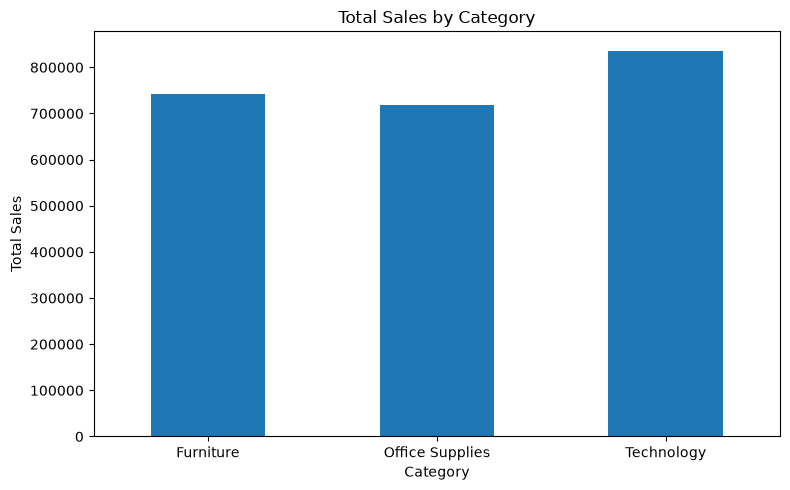

In [40]:
import matplotlib.pyplot as plt

category_analysis["Total_Sales"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by Category"
)

plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

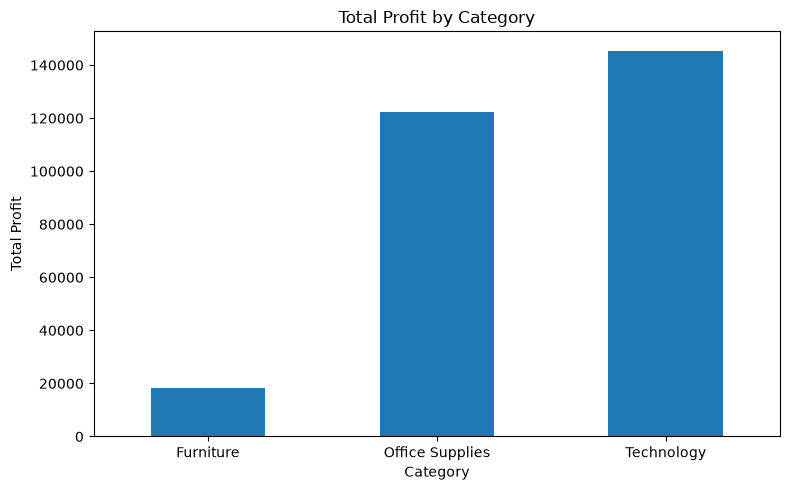

In [41]:
category_analysis["Total_Profit"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Profit by Category"
)

plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

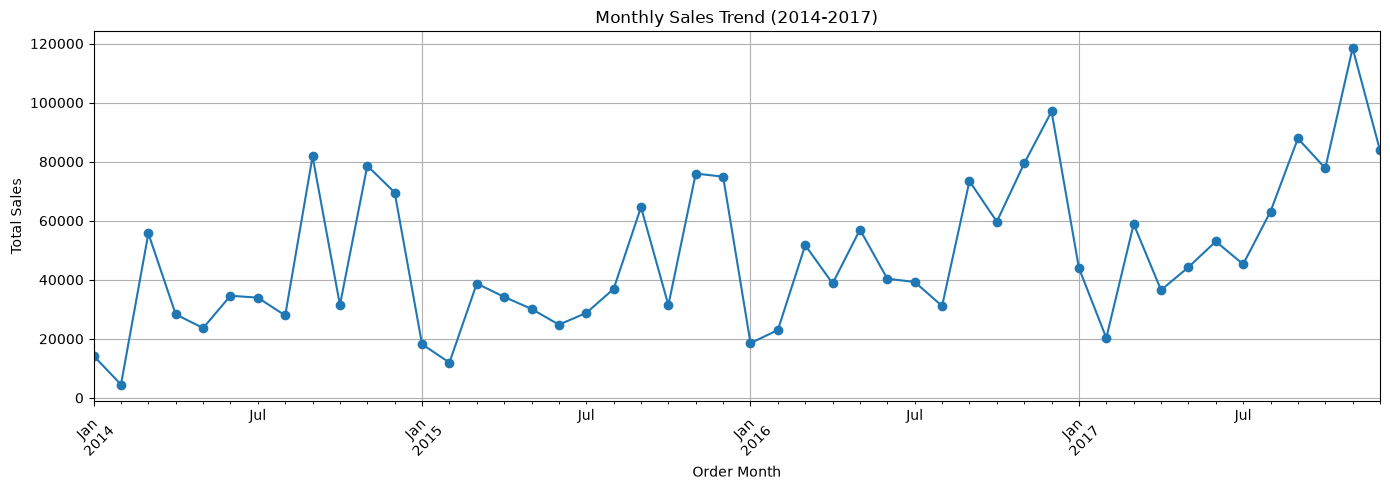

In [42]:
monthly_analysis["Total_Sales"].plot(
    kind="line",
    figsize=(14, 5),
    marker="o",
    title="Monthly Sales Trend (2014-2017)"
)

plt.xlabel("Order Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

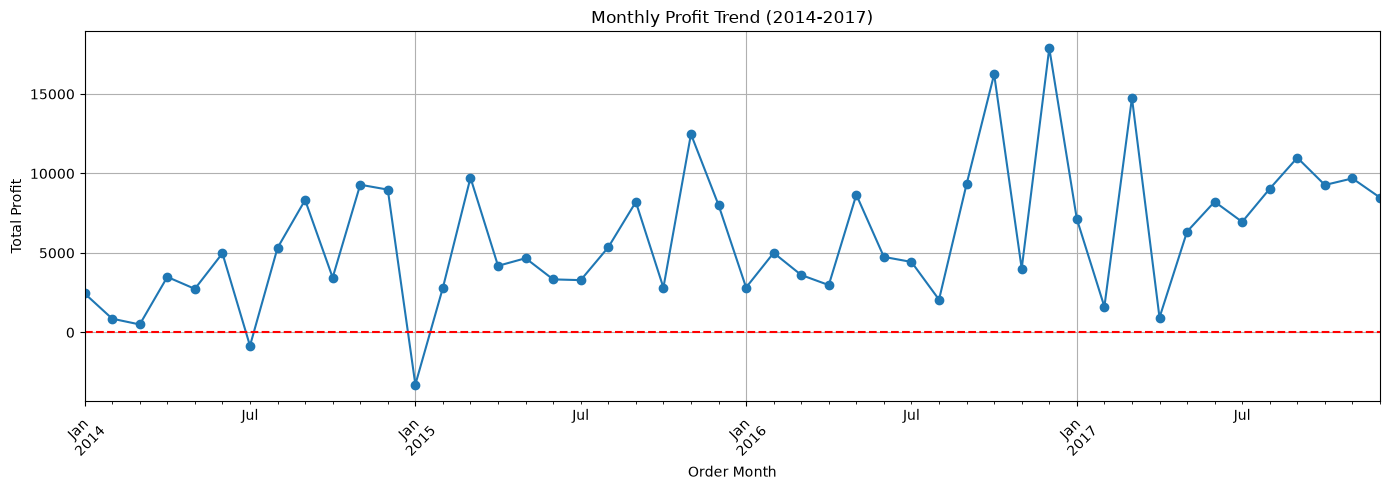

In [43]:
monthly_analysis["Total_Profit"].plot(
    kind="line",
    figsize=(14, 5),
    marker="o",
    title="Monthly Profit Trend (2014-2017)"
)

plt.xlabel("Order Month")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.axhline(y=0, color="red", linestyle="--")
plt.grid(True)
plt.tight_layout()
plt.show()

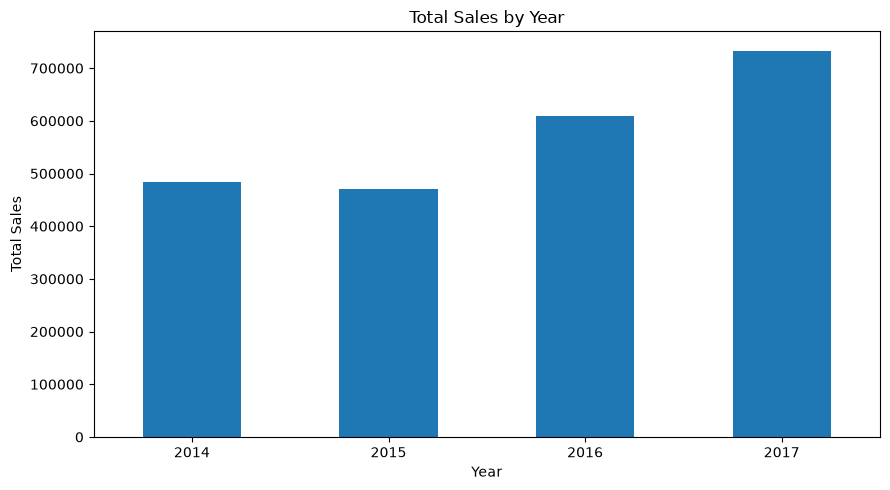

In [44]:
yearly_analysis["Total_Sales"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Total Sales by Year"
)

plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

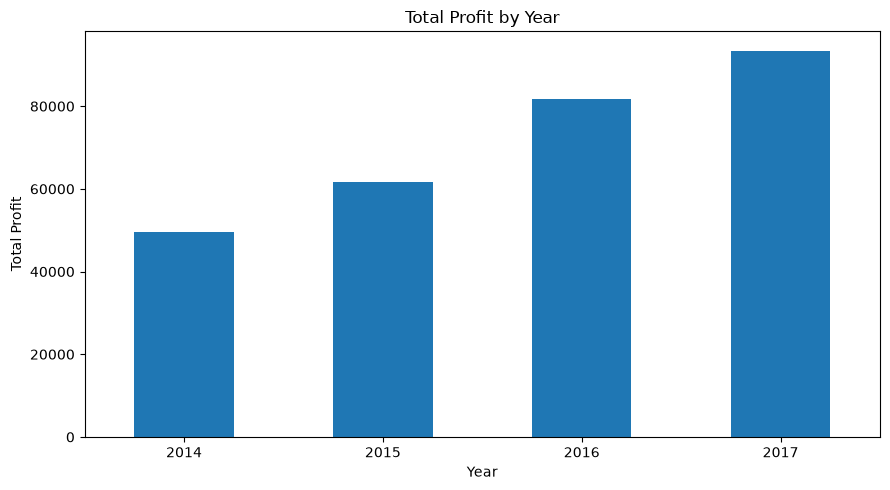

In [45]:
yearly_analysis["Total_Profit"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Total Profit by Year"
)

plt.xlabel("Year")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

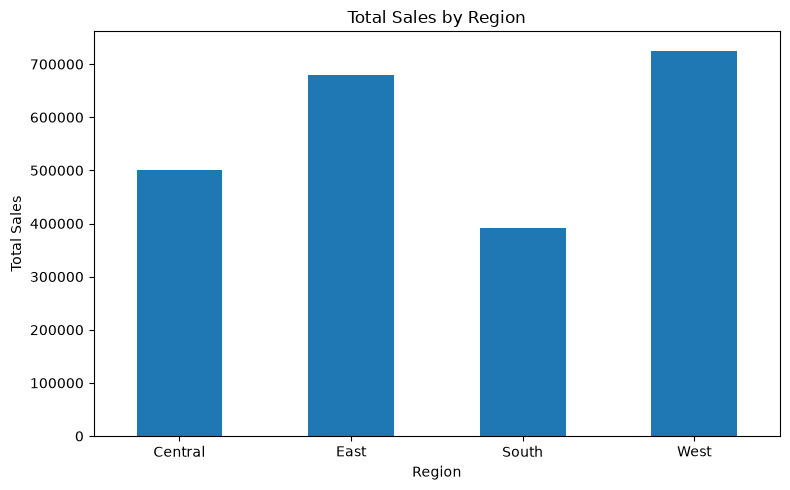

In [46]:
regional_analysis["Total_Sales"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by Region"
)

plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

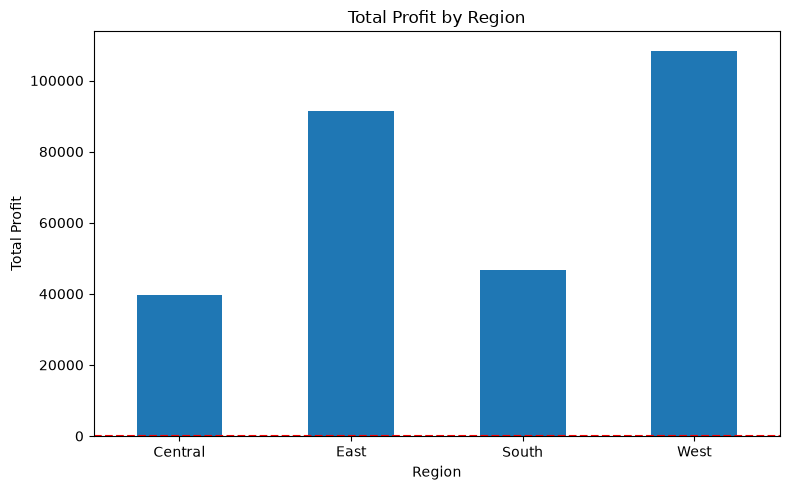

In [47]:
regional_analysis["Total_Profit"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Profit by Region"
)

plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.axhline(y=0, color="red", linestyle="--")
plt.tight_layout()
plt.show()

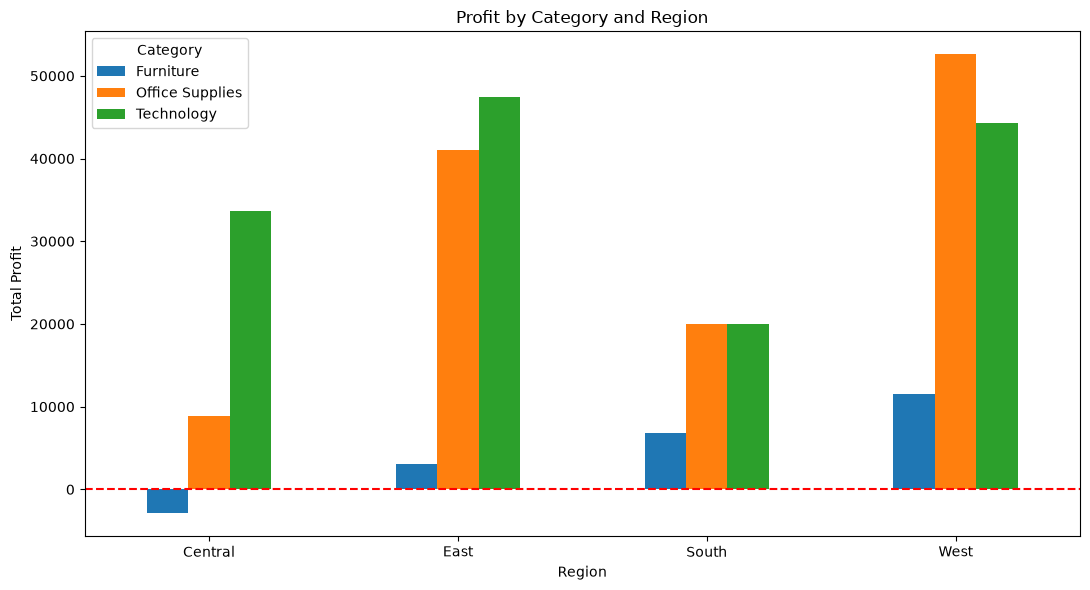

In [48]:
region_category_analysis.plot(
    kind="bar",
    figsize=(11, 6),
    title="Profit by Category and Region"
)

plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.axhline(y=0, color="red", linestyle="--")
plt.legend(title="Category")
plt.tight_layout()
plt.show()

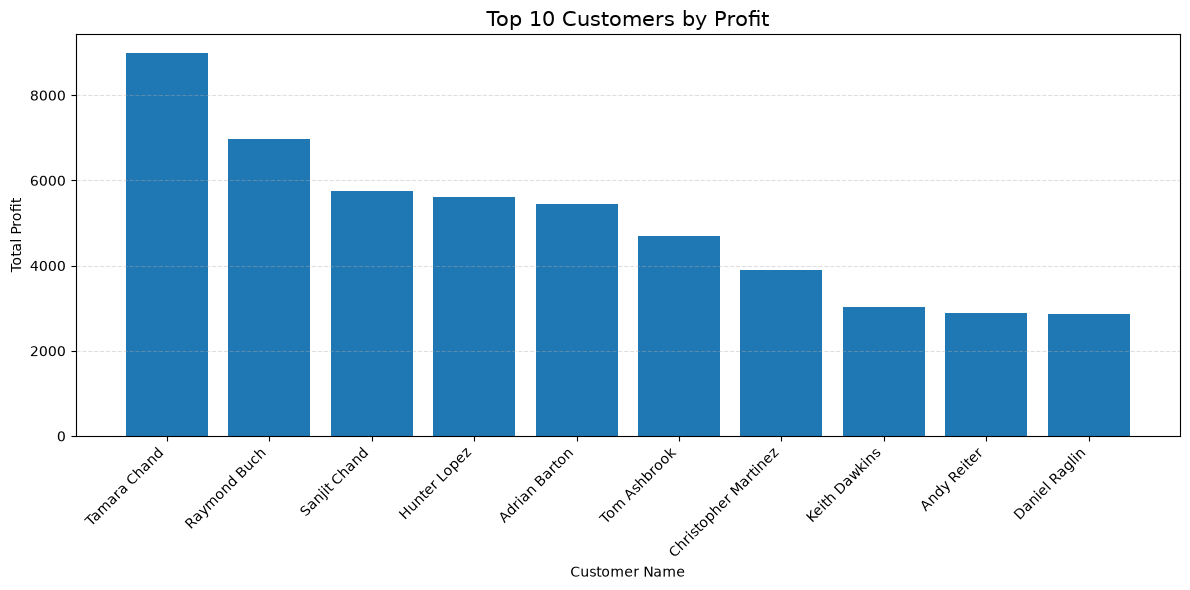

In [49]:

top_customers = customer_analysis.sort_values(
    "Total_Profit",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_customers.index.get_level_values("Customer Name"),
    top_customers["Total_Profit"]
)

plt.title("Top 10 Customers by Profit", fontsize=15)
plt.xlabel("Customer Name")
plt.ylabel("Total Profit")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


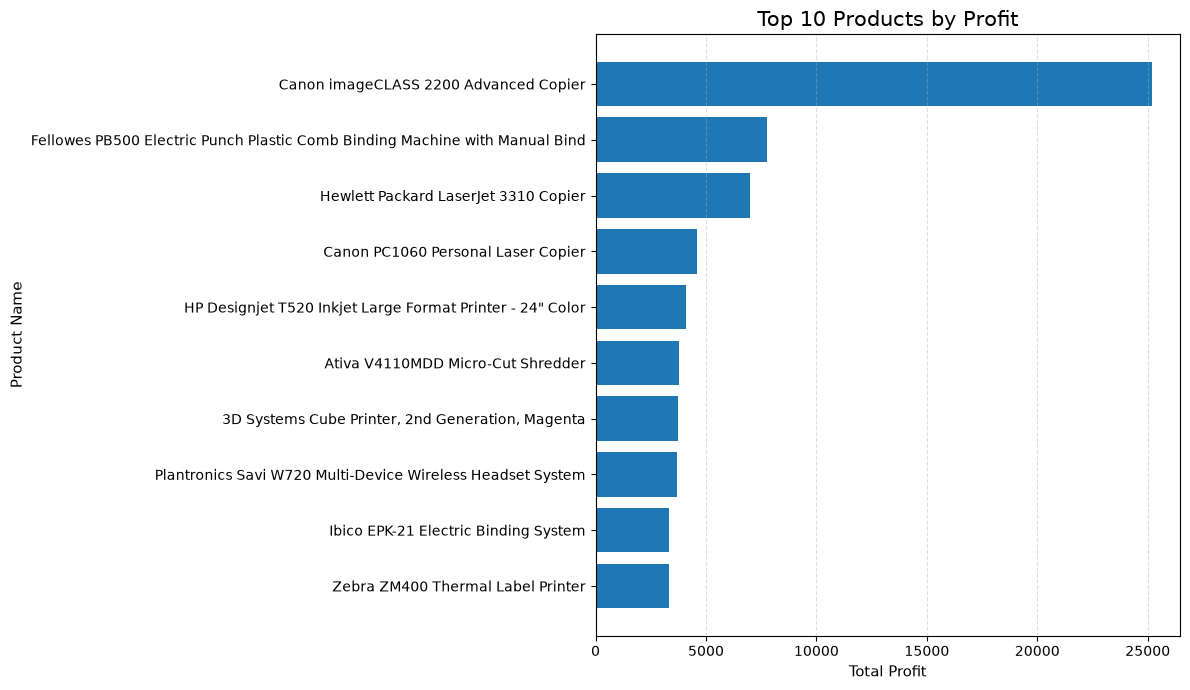

In [50]:
top_products = product_analysis.sort_values(
    "Total_Profit",
    ascending=False
).head(10).sort_values("Total_Profit")

plt.figure(figsize=(12, 7))

plt.barh(
    top_products.index.get_level_values("Product Name"),
    top_products["Total_Profit"]
)

plt.title("Top 10 Products by Profit", fontsize=15)
plt.xlabel("Total Profit", fontsize=11)
plt.ylabel("Product Name", fontsize=11)

plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

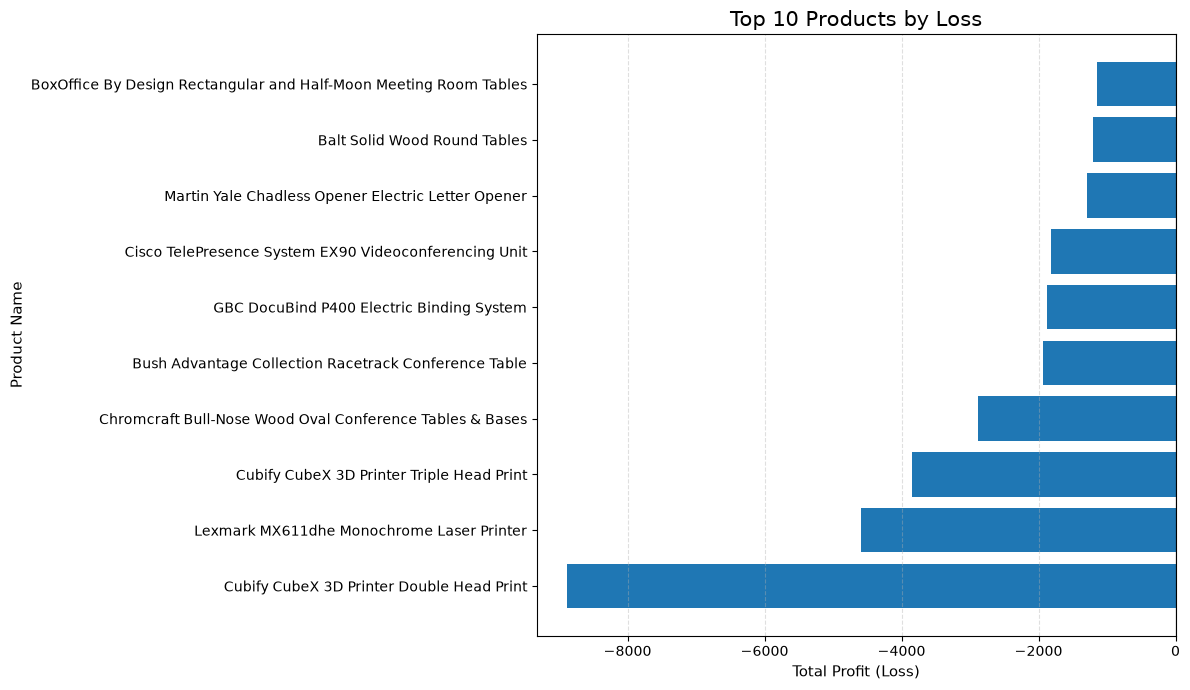

In [51]:
top_loss_products = product_analysis.sort_values(
    "Total_Profit",
    ascending=True
).head(10)

top_loss_products = top_loss_products.sort_values("Total_Profit")

plt.figure(figsize=(12, 7))

plt.barh(
    top_loss_products.index.get_level_values("Product Name"),
    top_loss_products["Total_Profit"]
)

plt.title("Top 10 Products by Loss", fontsize=15)
plt.xlabel("Total Profit (Loss)", fontsize=11)
plt.ylabel("Product Name", fontsize=11)

plt.axvline(x=0, color="black", linewidth=0.8)
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

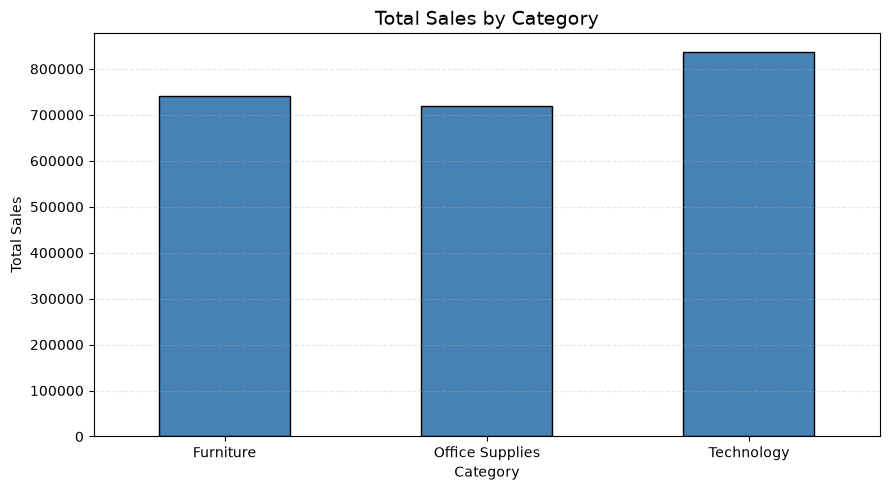

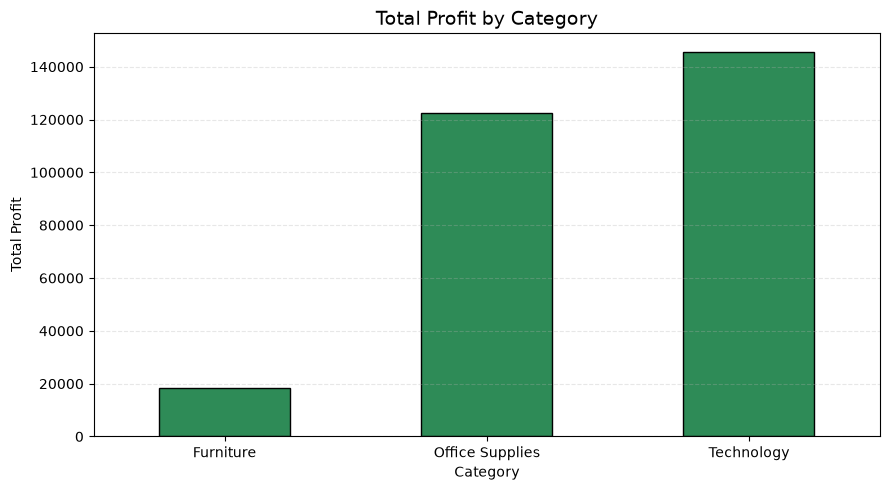

In [52]:

# Sales by Category

plt.figure(figsize=(9, 5))

category_analysis["Total_Sales"].plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)

plt.title("Total Sales by Category", fontsize=14)
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


# Profit by Category

plt.figure(figsize=(9, 5))

category_analysis["Total_Profit"].plot(
    kind="bar",
    color="seagreen",
    edgecolor="black"
)

plt.title("Total Profit by Category", fontsize=14)
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


## 16. Business Insights and Recommendations

### 1. Discount Strategy
High discounts are associated with lower profitability.
Discounts of 30% or more generally resulted in negative average profits.
The company should review its discount policies, especially for products with consistently negative profit margins.

### 2. Product Performance
Tables, Bookcases, and Supplies generated negative total profits.
The company should investigate pricing, discounts, and costs for these products.
Copiers generated the highest total profit among sub-categories.

### 3. Regional Performance
The West region achieved the highest sales, total profit, and profit margin.
The Central region showed the lowest profit margin.
The company should investigate the performance of Furniture in the Central region.

### 4. Customer Segments
The Consumer segment generated the highest total sales and profit.
However, Home Office had the highest average order value and profit margin.
Marketing strategies could be adjusted based on the characteristics of each segment.

### 5. Sales and Profit Growth
Sales and profit increased significantly between 2015 and 2017.
However, in 2017, sales growth exceeded profit growth.
The company should investigate whether discounts or changes in product mix affected profitability.

## 17. Executive Summary

This project analyzes retail sales data from 2014 to 2017, 
covering 9,994 transactions and 21 variables.

The analysis focuses on sales performance, profitability, 
discount strategies, product performance, customer segments, 
regional performance, and shipping methods.

### Key Findings

- Total sales increased from approximately $484K in 2014 
  to $733K in 2017.
- Total profit reached approximately $93K in 2017.
- The West region generated the highest total sales and profit.
- The Central region had the lowest profit margin.
- Tables generated the largest cumulative loss among sub-categories.
- High discount levels were associated with negative average profits.
- The Consumer segment generated the highest total sales, 
  while Home Office had the highest profit margin.

### Conclusion

The business experienced overall growth between 2014 and 2017.
However, profitability varied across products, regions, and customer segments.

Reviewing discount policies, investigating loss-making products,
and improving regional performance could help increase profitability.